## **Exercise: Time Series (ARIMA)**

**Gunakan dataset AirPassengers**

1. Lakukan EDA.
2. Cek apakah data sudah stasioner? Jika belum, lakukan differencing.
3. Gunakan ADF test untuk mengecek stasionerity data secara statistik.
4. Cari model ARIMA terbaik melalui grafik ACF & PACF.
5. Buat modelnya dan lakukan forecasting untuk periode 1 tahun.

In [1]:
import numpy as np 
import pandas as pd 
import seaborn as sns 
import matplotlib.pyplot as plt 

from datetime import datetime

import statsmodels.api as sm
from statsmodels.api import OLS
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima_model import ARIMA
from statsmodels.tsa.stattools import adfuller

import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv('AirPassengers.csv')
df

,Month,#Passengers
0,1949-01,112
1,1949-02,118
2,1949-03,132
3,1949-04,129
4,1949-05,121
...,...,...
139,1960-08,606
140,1960-09,508
141,1960-10,461
142,1960-11,390


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 144 entries, 0 to 143
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Month        144 non-null    object
 1   #Passengers  144 non-null    int64 
dtypes: int64(1), object(1)
memory usage: 2.4+ KB


In [9]:
df = df.rename(columns={'Month': 'Date'})
df = df.rename(columns={'#Passengers': 'Passengers'})

In [10]:
df['Date'] = pd.to_datetime(df['Date'])

In [11]:
df['Date'] = df['Date'].dt.date
df.head()

,Date,Passengers
0,1949-01-01,112
1,1949-02-01,118
2,1949-03-01,132
3,1949-04-01,129
4,1949-05-01,121


## **EDA**

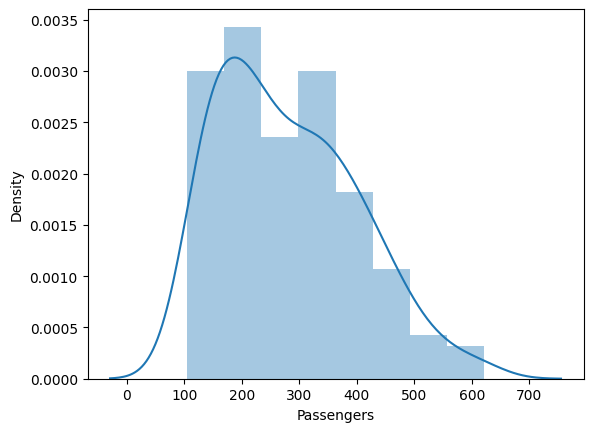

In [12]:
sns.distplot(df['Passengers']);

In [13]:
df['Passengers'].skew()

0.5831604861560892

In [14]:
import plotly.graph_objects as go

fig = go.Figure([go.Scatter(name='true', x=df['Date'], y=df['Passengers'])])
fig.update_xaxes(rangeslider_visible=True)
fig.show()

## **Stationarity**

### **Cek stationarity dengan menggunakan adfuller test**

**Hypothesis untuk adfuller test:**

$H_0$: Data tidak stasioner

$H_1$: Data stasioner

In [15]:
adf = adfuller(df['Passengers']) 
adf

(0.8153688792060472,
 0.991880243437641,
 13,
 130,
 {'1%': -3.4816817173418295,
  '5%': -2.8840418343195267,
  '10%': -2.578770059171598},
 996.6929308390189)

In [16]:
adf = adfuller(df['Passengers'])
print(adf)

alpha = 0.05
if adf[1] <= alpha:
    print('Reject null hypothesis, The data is stationary')
else:
    print('Failed to reject null hypothesis, The data is not stationary')

(0.8153688792060472, 0.991880243437641, 13, 130, {'1%': -3.4816817173418295, '5%': -2.8840418343195267, '10%': -2.578770059171598}, 996.6929308390189)
Failed to reject null hypothesis, The data is not stationary


In [17]:
# buat DataFrame untuk data yang stasioner
df_stationary = df.copy()

In [18]:
# differencing 1 kali
df_stationary['Passengers_diff1'] = df_stationary['Passengers'].diff()

# differencing 2 kali
df_stationary['Passengers_diff2'] = df_stationary['Passengers'].diff().diff()

In [19]:
df_stationary

,Date,Passengers,Passengers_diff1,Passengers_diff2
0,1949-01-01,112,NaN,NaN
1,1949-02-01,118,6.0,NaN
2,1949-03-01,132,14.0,8.0
3,1949-04-01,129,-3.0,-17.0
4,1949-05-01,121,-8.0,-5.0
...,...,...,...,...
139,1960-08-01,606,-16.0,-103.0
140,1960-09-01,508,-98.0,-82.0
141,1960-10-01,461,-47.0,51.0
142,1960-11-01,390,-71.0,-24.0


In [20]:
# drop baris pertama dan kedua
df_stationary = df_stationary.dropna()

In [21]:
# Dataframe untuk modeling
df_stationary

,Date,Passengers,Passengers_diff1,Passengers_diff2
2,1949-03-01,132,14.0,8.0
3,1949-04-01,129,-3.0,-17.0
4,1949-05-01,121,-8.0,-5.0
5,1949-06-01,135,14.0,22.0
6,1949-07-01,148,13.0,-1.0
...,...,...,...,...
139,1960-08-01,606,-16.0,-103.0
140,1960-09-01,508,-98.0,-82.0
141,1960-10-01,461,-47.0,51.0
142,1960-11-01,390,-71.0,-24.0


In [22]:
# cek setelah dilakukan differencing 1x apakah sudah stasioner

adf_stat = adfuller(df_stationary['Passengers_diff1'])
print(adf_stat[1])

alpha = 0.05
if adf_stat[1] <= alpha:
    print('Reject null hypothesis; The data is stationary')
else:
    print('Failed to reject null hypothesis; The data is not stationary')

0.05365549915890894
Failed to reject null hypothesis; The data is not stationary


In [23]:
# cek setelah dilakukan differencing 2x apakah sudah stasioner

adf_stat = adfuller(df_stationary['Passengers_diff2'])
print(adf_stat[1])

alpha = 0.05
if adf_stat[1] <= alpha:
    print('Reject null hypothesis; The data is stationary')
else:
    print('Failed to reject null hypothesis; The data is not stationary')

2.7328918500143186e-29
Reject null hypothesis; The data is stationary


**Data sudah stasioner setelah 2 kali differencing**

Differencing dilakukan agar data menjadi stasioner

### **Cek stationarity dengan menggunakan grafik ACF dan PACF**


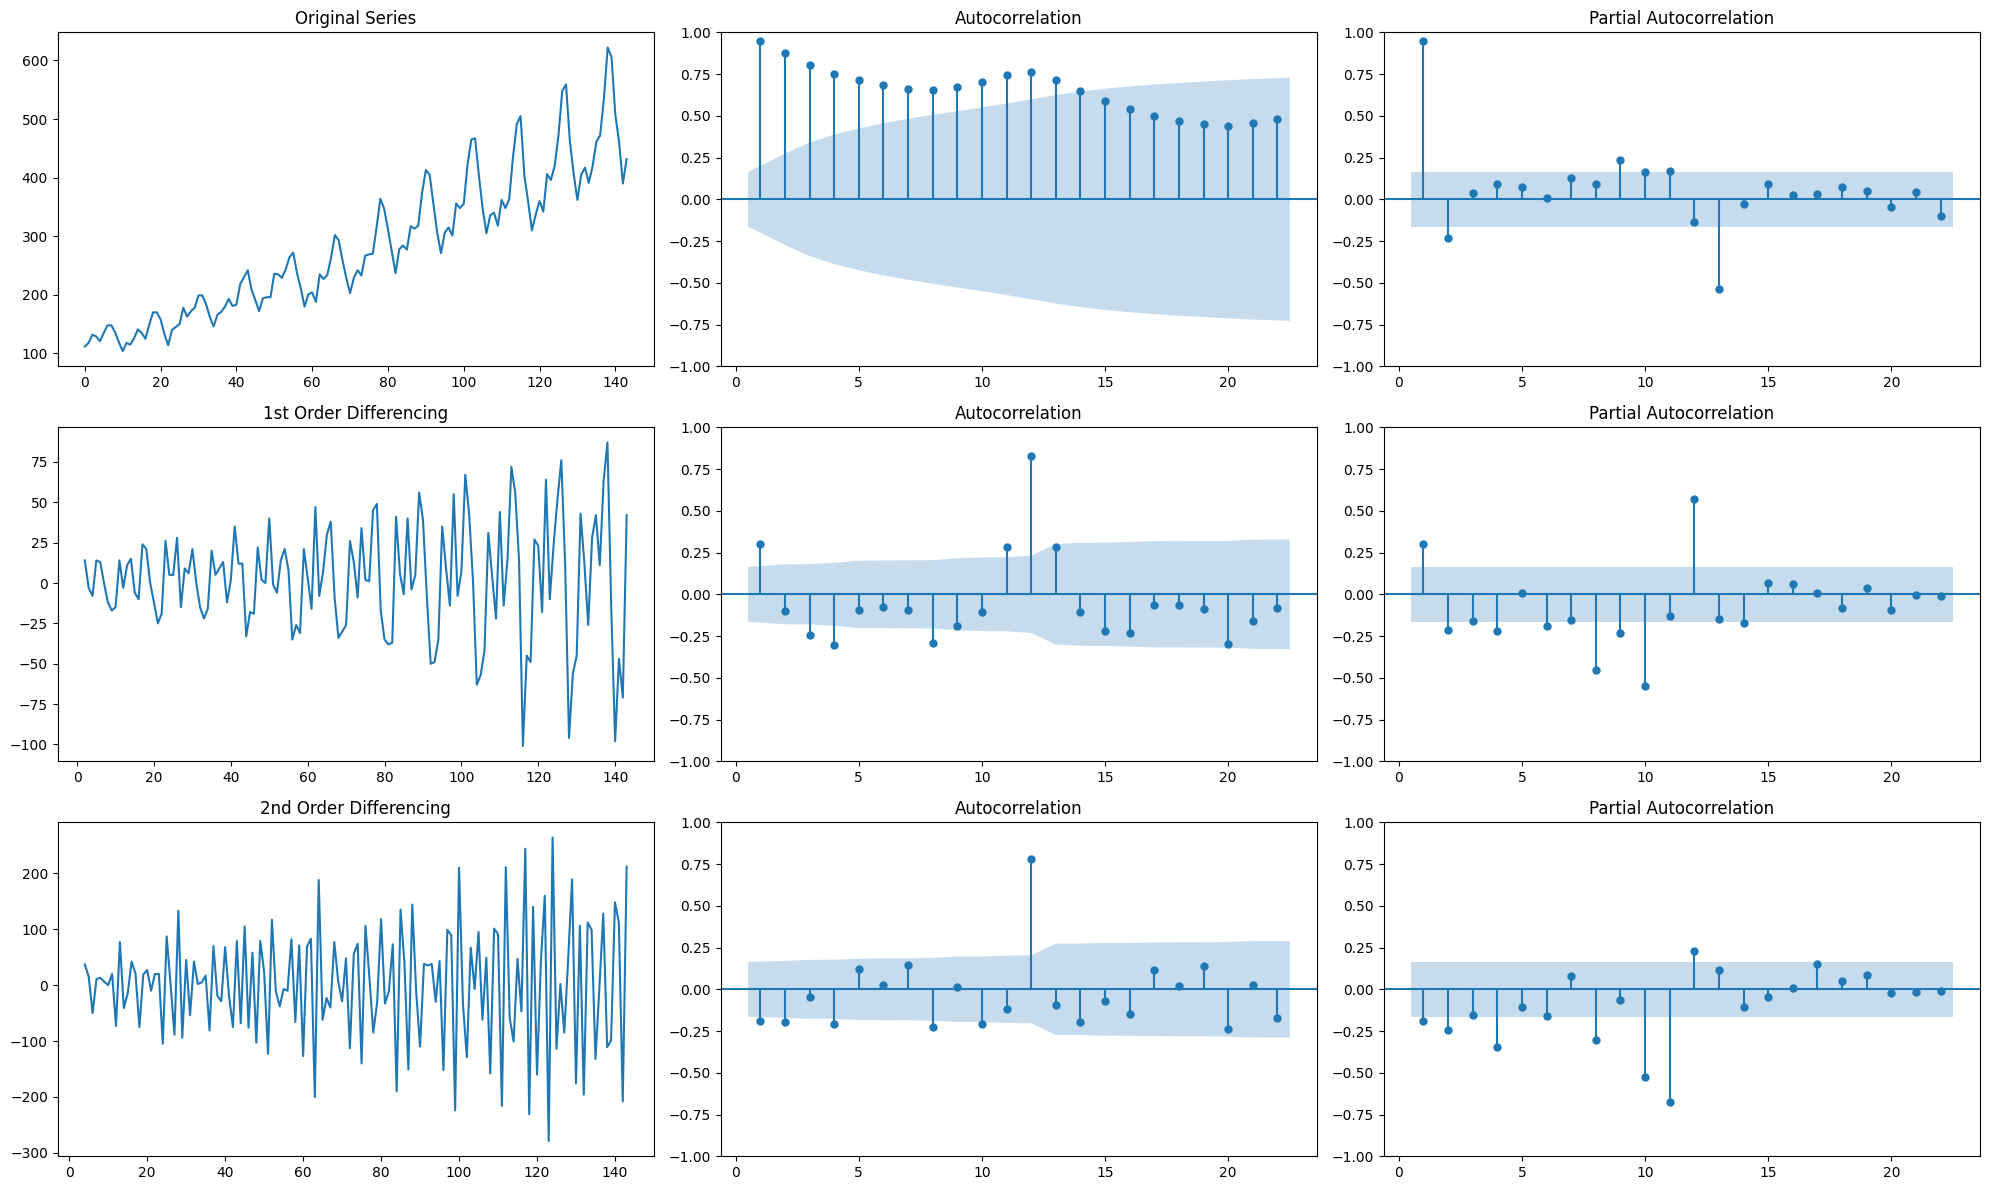

In [24]:
fig, axes = plt.subplots(3, 3, figsize = (20,12))

# Original Series
axes[0, 0].plot(df['Passengers']); 
axes[0, 0].set_title('Original Series')
plot_acf(df['Passengers'], ax=axes[0, 1], zero = False)
plot_pacf(df['Passengers'], ax=axes[0, 2], zero = False)

# 1st Differencing
axes[1, 0].plot(df_stationary['Passengers_diff1']); 
axes[1, 0].set_title('1st Order Differencing')
plot_acf(df_stationary['Passengers_diff1'].dropna(), ax=axes[1, 1], zero = False)
plot_pacf(df_stationary['Passengers_diff1'].dropna(), ax=axes[1, 2], zero = False)

# 2nd Differencing
axes[2, 0].plot(df_stationary['Passengers_diff2'].diff().diff()); 
axes[2, 0].set_title('2nd Order Differencing')
plot_acf(df_stationary['Passengers_diff2'].dropna(), ax=axes[2, 1], zero = False)
plot_pacf(df_stationary['Passengers_diff2'].dropna(), ax=axes[2, 2], zero = False)

plt.tight_layout()
plt.show()

**Interpretasi**

- Pada original series, grafik ACF (Autocorrelation) masih slowly tail-off. Artinya datanya tidak stasioner
- Kita lakukan differencing orde ke-1. 
- Jika melihat dari grafik ACF (Autocorrelation) yang tidak lagi slowly tail-off, data terlihat sudah stasioner pada differensing orde ke-1.
- Kita coba lihat juga ketika dilakukan differenceing orde ke-2
- Datanya juga sudah terlihat stasioner.  

## **Modeling**

- Penentuan model ARIMA bisa dilakukan secara manual dengan melihat pada grafik ACF dan PACF di atas. Penentuannya secara subjektif.
- Jika melihat dari grafik ACF dn PACF, data stasioner pada differencing orde ke-1. Berarti d=1.
- Lihat grafik ACF. Bar pertama yang ada di luar zona biru (confidence interval) dipilih sebagai q (MA). Berarti q=1
- Lihat grafik PACF. Bar pertama yang ada di luar zona biru (confidence interval) dipilih sebagai p (AR). Berarti p=1

Grafik ACF cut-off, grafik PACF juga cut-off. Jadi kandidatnya adalah
- ARIMA (p, d, q) = (13,2,0)
- ARIMA (p, d, q) = (0,2,12)

> <br>
> Model Specification (stationary condition) :

> - PACF Cut off after lag p, ACF Tails Off --> AR(p)
> - ACF Cut off after lag q, PACF Tails Off --> MA(q)
> - PACF Cut off after lag p, ACF Cut off after lag q --> AR(p) or MA(q)
> - ACF and PACF tails off -->  choose all possible combination
<br>

Bisa juga kita mencari model ARIMA terbaik secara otomatis menggunakan auto_arima dari pmdarima. Nilai AIC paling kecil menunjukkan model terbaik. 

In [28]:
import pmdarima as pmd

# arima_model = pmd.auto_arima(
#     df_stationary['Passengers_Stationary_2'],
#     start_p=1,
#     start_q=1, 
#     trace=True
# )

In [29]:
arima_model = pmd.auto_arima(
    df_stationary['Passengers'],
    start_p=1,
    start_q=1, 
    trace=True,
)

Performing stepwise search to minimize aic
 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=1378.648, Time=0.14 sec
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=1397.391, Time=0.01 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=1385.745, Time=0.03 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=1381.200, Time=0.05 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=1395.947, Time=0.01 sec
 ARIMA(2,1,1)(0,0,0)[0] intercept   : AIC=inf, Time=0.16 sec
 ARIMA(1,1,2)(0,0,0)[0] intercept   : AIC=inf, Time=0.09 sec
 ARIMA(0,1,2)(0,0,0)[0] intercept   : AIC=1380.880, Time=0.06 sec
 ARIMA(2,1,0)(0,0,0)[0] intercept   : AIC=1380.391, Time=0.04 sec
 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=inf, Time=0.25 sec
 ARIMA(1,1,1)(0,0,0)[0]             : AIC=1377.155, Time=0.04 sec
 ARIMA(0,1,1)(0,0,0)[0]             : AIC=1379.584, Time=0.02 sec
 ARIMA(1,1,0)(0,0,0)[0]             : AIC=1384.074, Time=0.02 sec
 ARIMA(2,1,1)(0,0,0)[0]             : AIC=1360.865, Time=0.05 sec
 ARIMA(2,1,0)(0,0,0)[0]             : AIC=1378.9

**Kandidat model:**
1. ARIMA(13, 2, 0)
1. ARIMA(0, 2, 12)
2. ARIMA(5, 1, 4)

In [30]:
# from statsmodels.tsa.arima_model import ARIMA
from statsmodels.tsa.arima.model import ARIMA

In [31]:
model1 = ARIMA(df['Passengers'], order=(13,2,0))
model1_fit = model1.fit()

print(model1_fit.summary())

                               SARIMAX Results                                
Dep. Variable:             Passengers   No. Observations:                  144
Model:                ARIMA(13, 2, 0)   Log Likelihood                -564.871
Date:                Mon, 24 Jun 2024   AIC                           1157.742
Time:                        13:15:05   BIC                           1199.123
Sample:                             0   HQIC                          1174.557
                                - 144                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -1.1118      0.123     -9.062      0.000      -1.352      -0.871
ar.L2         -1.1789      0.189     -6.232      0.000      -1.550      -0.808
ar.L3         -1.1095      0.190     -5.844      0.0

In [32]:
model2 = ARIMA(df['Passengers'], order = (0, 2, 12))
model2_fit = model2.fit()
print(model2_fit.summary())

                               SARIMAX Results                                
Dep. Variable:             Passengers   No. Observations:                  144
Model:                ARIMA(0, 2, 12)   Log Likelihood                -649.043
Date:                Mon, 24 Jun 2024   AIC                           1324.087
Time:                        13:15:15   BIC                           1362.513
Sample:                             0   HQIC                          1339.701
                                - 144                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.5010    375.614     -0.001      0.999    -736.691     735.689
ma.L2         -0.0712    184.402     -0.000      1.000    -361.492     361.350
ma.L3         -0.1848    156.180     -0.001      0.9

In [33]:
model3 = ARIMA(df['Passengers'], order = (5, 1, 4))
model3_fit = model3.fit()
print(model3_fit.summary())

                               SARIMAX Results                                
Dep. Variable:             Passengers   No. Observations:                  144
Model:                 ARIMA(5, 1, 4)   Log Likelihood                -673.541
Date:                Mon, 24 Jun 2024   AIC                           1367.082
Time:                        13:15:29   BIC                           1396.710
Sample:                             0   HQIC                          1379.122
                                - 144                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.2249      0.083      2.708      0.007       0.062       0.388
ar.L2          1.4041      0.083     16.873      0.000       1.241       1.567
ar.L3         -0.6108      0.143     -4.259      0.0

## **Forecasting**
sama seperti predict

Kandidat:
- ARIMA(13,2,0)
- ARIMA(0,2,12)
- ARIMA(5,1,4)
<br><br>
- Bisa juga  coba: ARIMA(13,2,12)  --> berdasarkan bar paling tinggi pada grafik ACF PACF 


In [34]:
model = ARIMA(df['Passengers'], order = (13, 2, 0))
model_final = model.fit()

In [35]:
# prediksi jumlah passenger 12 bulan ke depan (sepanjang tahun 1961)

forecast_length = 12

forecast_result = model_final.forecast(forecast_length)
forecast_result

144    454.524505
145    417.818486
146    445.618552
147    486.905417
148    507.015140
149    562.800787
150    650.624670
151    630.848828
152    545.500304
153    487.171474
154    426.344957
155    459.542809
Name: predicted_mean, dtype: float64

In [36]:
print('Forecasted Value ','\n', forecast_result)


Forecasted Value  
 144    454.524505
145    417.818486
146    445.618552
147    486.905417
148    507.015140
149    562.800787
150    650.624670
151    630.848828
152    545.500304
153    487.171474
154    426.344957
155    459.542809
Name: predicted_mean, dtype: float64


In [37]:
# print('Forecasted Value', '\n', forecast_result[0], '\n')
# print('Forecasted SE', '\n', forecast_result[1], '\n')
# print('Forecasted confidence interval', '\n', forecast_result[2])

In [38]:
df.tail(6)

,Date,Passengers
138,1960-07-01,622
139,1960-08-01,606
140,1960-09-01,508
141,1960-10-01,461
142,1960-11-01,390
143,1960-12-01,432


In [39]:
# membuat tanggal untuk hasil forcasting
Month = []

for i in range(1, forecast_length+1):
    Month.append('1961-'+str(i)+'-01')

Month    

['1961-1-01',
 '1961-2-01',
 '1961-3-01',
 '1961-4-01',
 '1961-5-01',
 '1961-6-01',
 '1961-7-01',
 '1961-8-01',
 '1961-9-01',
 '1961-10-01',
 '1961-11-01',
 '1961-12-01']

In [41]:
df_forecast = pd.DataFrame({
    'Date': Month,
    'Passengers': forecast_result,
})

df_forecast

,Date,Passengers
144,1961-1-01,454.524505
145,1961-2-01,417.818486
146,1961-3-01,445.618552
147,1961-4-01,486.905417
148,1961-5-01,507.015140
149,1961-6-01,562.800787
150,1961-7-01,650.624670
151,1961-8-01,630.848828
152,1961-9-01,545.500304
153,1961-10-01,487.171474


In [42]:
# df_forecast.iloc[:12,:][['Date', 'Passengers']]

In [43]:
df_forecast.iloc[:1,:][['Date', 'Passengers']]

,Date,Passengers
144,1961-1-01,454.524505


In [45]:
# agar garis dataset awal dan garis hasil forcasting tersambung
# df = df.append(df_forecast.iloc[:1,:][['Date', 'Passengers']])

In [527]:
# df.iloc[-7:, :]

,Date,Passengers
138,1960-07-01,622.000000
139,1960-08-01,606.000000
140,1960-09-01,508.000000
141,1960-10-01,461.000000
142,1960-11-01,390.000000
143,1960-12-01,432.000000
144,1961-1-01,451.408556


In [528]:
# Gabungan dari dataset awal dan hasil forecasting

# df_merged = df
# df_merged = df_merged.append(df_forecast.iloc[:12,:][['Date', 'Passengers']], ignore_index=True)
# df_merged.tail(24)

In [46]:
fig = go.Figure()

# lineplot dataset awal
fig.add_trace(go.Scatter(name='Actual', x=df['Date'], y=df['Passengers']))

# lineplot hasil forecasting
fig.add_trace(go.Scatter(name='Forecast', x=df_forecast['Date'], y=df_forecast['Passengers']))          # forecast

fig.update_xaxes(rangeslider_visible = True)
fig.show()

In [50]:
# sort out the best paramater

list_p = list(range(0,14)) # AR
list_d = list(range(1,3))  # I
list_q = list(range(0,5)) # MA

list_pdq = []
list_aic = []

for p in list_p:
    for d in list_d:
        for q in list_q:

            list_pdq.append((p,d,q))

            model_loop = ARIMA(df['Passengers'], order=(p,d,q))
            model_loop.initialize_approximate_diffuse() # this line
            model_loop_fit = model_loop.fit()

            aic_score = model_loop_fit.aic
            list_aic.append(aic_score)
      

In [58]:
best_aic = pd.DataFrame({
    'pdq': list_pdq,
    'AIC': list_aic
}).sort_values(by='AIC').head(20)

best_aic

,pdq,AIC
118,"(11, 2, 3)",1204.526324
116,"(11, 2, 1)",1204.719058
119,"(11, 2, 4)",1206.620257
117,"(11, 2, 2)",1208.390823
115,"(11, 2, 0)",1218.628222
123,"(12, 1, 3)",1221.813994
121,"(12, 1, 1)",1223.032155
109,"(10, 2, 4)",1223.740529
122,"(12, 1, 2)",1224.783480
136,"(13, 2, 1)",1225.650259


In [ ]:
# best_aic = pd.DataFrame({
#     'pdq': list_pdq,
#     'AIC': list_aic
# }).sort_values(by='AIC').head(20)

# best_aic

,pdq,AIC
433,"(13, 2, 1)",1144.638112
372,"(11, 2, 4)",1146.186011
371,"(11, 2, 3)",1146.656597
375,"(11, 2, 7)",1146.796165
465,"(14, 2, 1)",1147.498332
373,"(11, 2, 5)",1147.770838
400,"(12, 2, 0)",1148.350066
369,"(11, 2, 1)",1148.493848
374,"(11, 2, 6)",1148.813665
437,"(13, 2, 5)",1148.830418


In [55]:
model = ARIMA(df['Passengers'], order = (11, 2, 3))
model_final = model.fit()

# prediksi jumlah passenger 12 bulan ke depan (sepanjang tahun 1961)

forecast_length = 12

forecast_result = model_final.forecast(forecast_length)

# membuat tanggal untuk hasil forcasting
Month = []

for i in range(1, forecast_length+1):
    Month.append('1961-'+str(i)+'-01')

df_forecast = pd.DataFrame({
    'Date': Month,
    'Passengers': forecast_result,
})

In [56]:
df_forecast

,Date,Passengers
144,1961-1-01,448.831529
145,1961-2-01,419.547293
146,1961-3-01,450.196691
147,1961-4-01,491.314649
148,1961-5-01,511.240230
149,1961-6-01,567.273033
150,1961-7-01,656.230712
151,1961-8-01,635.328693
152,1961-9-01,548.003949
153,1961-10-01,493.634536


In [57]:
fig = go.Figure()

# lineplot dataset awal
fig.add_trace(go.Scatter(name='Actual', x=df['Date'], y=df['Passengers']))

# lineplot hasil forecasting
fig.add_trace(go.Scatter(name='Forecast', x=df_forecast['Date'], y=df_forecast['Passengers']))          # forecast

fig.update_xaxes(rangeslider_visible = True)
fig.show()